# 04 — Model Explainability and Background Sensitivity

Grad-CAM visualizations and experiments investigating whether predictions are sensitive to image backgrounds or cropping.

**Environment:** Google Colab with Google Drive mounted. Check paths and prerequisite artifacts before running.

These experiments depend on a trained model, test images, and preprocessing variables being available. They are analysis-only in intent, but run only after confirming the checkpoint and input paths.

Grad-CAM explainability

In [9]:
from google.colab import drive

drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
# 1. Set up Grad-Cam and load ResNet18

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import cv2

from PIL import Image
from pathlib import Path
from torchvision import models
import torch.nn as nn

# Define class names
class_names = [
    "bacterial_blight",
    "curl_virus",
    "fussarium_wilt",
    "healthy"
]

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Model checkpoint path
checkpoint_path = Path(
    "/content/gdrive/MyDrive/CottonGuard-AI/models/"
    "deep_learning/resnet18_finetuned_best.pth"
)

# Check checkpoint existence
assert checkpoint_path.exists(), f"Checkpoint not found: {checkpoint_path}"

# Load ResNet18 architecture
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(class_names))

# Load trained weights
state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state_dict)

# Move model to device
model = model.to(device)
model.eval()

print("ResNet18 loaded successfully.")
print("Device:", device)
print("Target layer: layer4")
print("Classes:", class_names)

ResNet18 loaded successfully.
Device: cuda
Target layer: layer4
Classes: ['bacterial_blight', 'curl_virus', 'fussarium_wilt', 'healthy']


In [ ]:
# 2. Implement the Grad-CAM function

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None

        self.forward_handle = target_layer.register_forward_hook(
            self._save_activations
        )

        self.backward_handle = target_layer.register_full_backward_hook(
            self._save_gradients
        )

    def _save_activations(self, module, inputs, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx=None):
        self.model.zero_grad(set_to_none=True)

        output = self.model(input_tensor)

        if class_idx is None:
            class_idx = int(output.argmax(dim=1).item())

        score = output[:, class_idx].sum()
        score.backward()

        weights = self.gradients.mean(
            dim=(2, 3), keepdim=True
        )

        cam = (weights * self.activations).sum(dim=1)
        cam = F.relu(cam)

        cam = F.interpolate(
            cam.unsqueeze(1),
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False
        ).squeeze()

        cam = cam.detach().cpu().numpy()
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        return cam, class_idx, output.detach()

    def close(self):
        self.forward_handle.remove()
        self.backward_handle.remove()


grad_cam = GradCAM(model, model.layer4)

print("Grad-CAM initialized.")

Grad-CAM initialized.


In [ ]:
# Load grouped test data for grad-cam

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/gdrive/MyDrive/CottonGuard-AI")

test_csv_path = PROJECT_DIR / "results" / "data" / "test_grouped.csv"

test_df_new = pd.read_csv(test_csv_path)

# Correct image paths for the current Google Drive mount
test_df_new["path"] = test_df_new["path"].str.replace(
    "/content/drive/MyDrive/",
    "/content/gdrive/MyDrive/",
    regex=False
)

print("Test dataset loaded successfully.")
print("Shape:", test_df_new.shape)
print("\nColumns:", test_df_new.columns.tolist())
print("\nFirst test sample:")
print(test_df_new.iloc[0][["path", "label"]])

print(
    "\nFirst image exists:",
    Path(test_df_new.iloc[0]["path"]).exists()
)

Test dataset loaded successfully.
Shape: (226, 6)

Columns: ['path', 'label', 'sha256', 'copies_found', 'group_id', 'split']

First test sample:
path     /content/gdrive/MyDrive/cotton/healthy/h141.jpg
label                                            healthy
Name: 0, dtype: object

First image exists: True


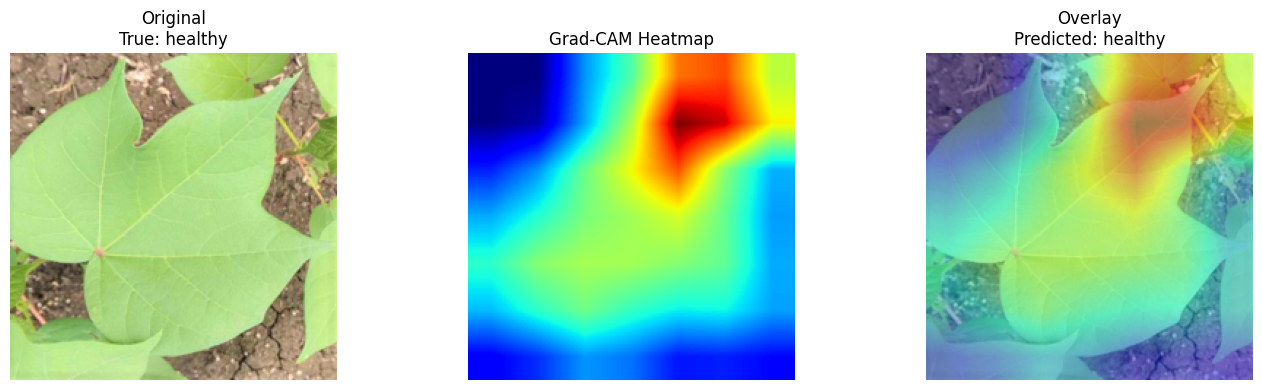

True label: healthy
Predicted label: healthy
Correct prediction: True


In [ ]:
# 3. Generate your first heatmap

import pandas as pd
from torchvision import transforms

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

sample_index = 0
sample_row = test_df_new.iloc[sample_index]

image_path = sample_row["path"]
true_label = sample_row["label"]

with Image.open(image_path) as img:
    original_image = img.convert("RGB").resize((224, 224))

input_tensor = eval_transform(original_image).unsqueeze(0).to(device)

model.eval()
cam, predicted_idx, logits = grad_cam.generate(input_tensor)

predicted_label = class_names[predicted_idx]

image_array = np.asarray(original_image)
heatmap = cv2.applyColorMap(
    np.uint8(255 * cam),
    cv2.COLORMAP_JET
)
heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

overlay = np.clip(
    0.55 * image_array + 0.45 * heatmap,
    0, 255
).astype(np.uint8)

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_array)
plt.title(f"Original\nTrue: {true_label}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title(f"Overlay\nPredicted: {predicted_label}")
plt.axis("off")

plt.tight_layout()
plt.show()

print("True label:", true_label)
print("Predicted label:", predicted_label)
print("Correct prediction:", true_label == predicted_label)

In [ ]:
# Create test dataset and dataloader

from torch.utils.data import Dataset, DataLoader
from PIL import Image

# Convert class names into numerical labels
class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(class_names)
}

class CottonTestDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = row["path"]
        label = row["label"]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = class_to_idx[label]

        return image, label


# Create test dataset
test_dataset = CottonTestDataset(
    dataframe=test_df_new,
    transform=eval_transform
)

# Create test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("Test DataLoader created successfully.")
print("Test samples:", len(test_dataset))
print("Number of batches:", len(test_loader))
print("Class mapping:", class_to_idx)

Test DataLoader created successfully.
Test samples: 226
Number of batches: 8
Class mapping: {'bacterial_blight': 0, 'curl_virus': 1, 'fussarium_wilt': 2, 'healthy': 3}


In [ ]:
# Inspect several test images

import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch

from PIL import Image
from torchvision import transforms

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

all_predictions = []
all_targets = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)

        all_predictions.extend(outputs.argmax(1).cpu().numpy())
        all_targets.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_targets = np.array(all_targets)

correct_indices = np.where(all_predictions == all_targets)[0]
wrong_indices = np.where(all_predictions != all_targets)[0]

print("Correct predictions:", len(correct_indices))
print("Incorrect predictions:", len(wrong_indices))

selected_indices = list(correct_indices[:4]) + list(wrong_indices[:2])

if len(selected_indices) == 0:
    selected_indices = list(range(min(6, len(test_df_new))))

fig, axes = plt.subplots(len(selected_indices), 3, figsize=(12, 4 * len(selected_indices)))

if len(selected_indices) == 1:
    axes = np.expand_dims(axes, axis=0)

for row_num, idx in enumerate(selected_indices):
    image_path = test_df_new.iloc[idx]["path"]
    true_label = test_df_new.iloc[idx]["label"]

    with Image.open(image_path) as img:
        original = img.convert("RGB").resize((224, 224))

    input_tensor = eval_transform(original).unsqueeze(0).to(device)

    cam, predicted_idx, logits = grad_cam.generate(input_tensor)
    predicted_label = class_names[predicted_idx]

    image_array = np.asarray(original)

    heatmap = cv2.applyColorMap(
        np.uint8(255 * cam),
        cv2.COLORMAP_JET
    )
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    overlay = np.clip(
        0.55 * image_array + 0.45 * heatmap,
        0, 255
    ).astype(np.uint8)

    axes[row_num, 0].imshow(image_array)
    axes[row_num, 0].set_title(f"True: {true_label}")
    axes[row_num, 0].axis("off")

    axes[row_num, 1].imshow(cam, cmap="jet")
    axes[row_num, 1].set_title("Grad-CAM")
    axes[row_num, 1].axis("off")

    axes[row_num, 2].imshow(overlay)
    axes[row_num, 2].set_title(f"Predicted: {predicted_label}")
    axes[row_num, 2].axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

Next step — Quantify background dependence

In [ ]:
# 1. Install and load automatic segmentation

import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

def create_leaf_focused_crop(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (224, 224))

    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    lower_green = np.array([20, 25, 20])
    upper_green = np.array([100, 255, 255])

    mask = cv2.inRange(hsv, lower_green, upper_green)

    kernel = np.ones((5, 5), np.uint8)
    mask = cv2.morphologyEx(
        mask, cv2.MORPH_CLOSE, kernel
    )
    mask = cv2.morphologyEx(
        mask, cv2.MORPH_OPEN, kernel
    )

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        return image, mask

    largest = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(largest)

    padding = 10
    x1 = max(0, x - padding)
    y1 = max(0, y - padding)
    x2 = min(image.shape[1], x + w + padding)
    y2 = min(image.shape[0], y + h + padding)

    crop = image[y1:y2, x1:x2]

    if crop.size == 0:
        return image, mask

    crop = cv2.resize(crop, (224, 224))

    return crop, mask

In [ ]:
# 2. Inspect the segmentation on six images

sample_indices = [0, 1, 2, 3, 4, 5]

fig, axes = plt.subplots(
    len(sample_indices), 3, figsize=(12, 4 * len(sample_indices))
)

for row_num, idx in enumerate(sample_indices):
    image_path = test_df_new.iloc[idx]["path"]
    true_label = test_df_new.iloc[idx]["label"]

    with Image.open(image_path) as img:
        original = np.asarray(
            img.convert("RGB").resize((224, 224))
        )

    crop, mask = create_leaf_focused_crop(image_path)

    axes[row_num, 0].imshow(original)
    axes[row_num, 0].set_title(f"Original: {true_label}")
    axes[row_num, 0].axis("off")

    axes[row_num, 1].imshow(mask, cmap="gray")
    axes[row_num, 1].set_title("Approximate green mask")
    axes[row_num, 1].axis("off")

    axes[row_num, 2].imshow(crop)
    axes[row_num, 2].set_title("Leaf-focused crop")
    axes[row_num, 2].axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# 2. COMPARE ORIGINAL AND CROPPED PREDICTIONS

import numpy as np
import pandas as pd
import torch

from PIL import Image
from pathlib import Path
from torchvision import transforms
from tqdm.auto import tqdm

# 1. Define evaluation transformations

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 2. Compare original and cropped image predictions

comparison_rows = []

model.eval()

for idx in tqdm(range(len(test_df_new))):

    row = test_df_new.iloc[idx]

    # Load original image
    with Image.open(row["path"]) as img:
        original = img.convert("RGB").resize((224, 224))

    # Generate leaf-focused crop
    cropped_array, _ = create_leaf_focused_crop(row["path"])
    cropped = Image.fromarray(cropped_array)

    # Transform images into tensors
    original_tensor = (
        eval_transform(original)
        .unsqueeze(0)
        .to(device)
    )

    cropped_tensor = (
        eval_transform(cropped)
        .unsqueeze(0)
        .to(device)
    )

    # Model predictions
    with torch.no_grad():

        original_logits = model(original_tensor)
        cropped_logits = model(cropped_tensor)

        original_probs = torch.softmax(
            original_logits, dim=1
        )[0]

        cropped_probs = torch.softmax(
            cropped_logits, dim=1
        )[0]

    # Predicted class indices
    original_idx = int(original_probs.argmax())
    cropped_idx = int(cropped_probs.argmax())

    true_idx = class_names.index(row["label"])

    # Store comparison results
    comparison_rows.append({

        "path": row["path"],
        "true_label": row["label"],

        "original_prediction": class_names[original_idx],
        "cropped_prediction": class_names[cropped_idx],

        "original_correct": original_idx == true_idx,
        "cropped_correct": cropped_idx == true_idx,

        "prediction_changed": original_idx != cropped_idx,

        "original_confidence": float(
            original_probs[original_idx]
        ),

        "cropped_confidence": float(
            cropped_probs[cropped_idx]
        )
    })

# 3. Create comparison DataFrame

comparison_df = pd.DataFrame(comparison_rows)

# 4. Calculate evaluation results

total_images = len(comparison_df)

changed_predictions = comparison_df[
    "prediction_changed"
].sum()

original_accuracy = comparison_df[
    "original_correct"
].mean()

cropped_accuracy = comparison_df[
    "cropped_correct"
].mean()

print("\n========== COMPARISON RESULTS ==========")

print("Images evaluated:", total_images)

print("Predictions changed:", changed_predictions)

print(
    "Original accuracy:",
    round(original_accuracy, 4)
)

print(
    "Cropped-image accuracy:",
    round(cropped_accuracy, 4)
)

print(
    "Original accuracy (%):",
    round(original_accuracy * 100, 2), "%"
)

print(
    "Cropped accuracy (%):",
    round(cropped_accuracy * 100, 2), "%"
)

# 5. Display images with changed predictions

print("\n========== CHANGED PREDICTIONS ==========")

display(
    comparison_df[
        comparison_df["prediction_changed"]
    ].head(15)
)

# 6. Save results to Google Drive

PROJECT_DIR = Path(
    "/content/gdrive/MyDrive/CottonGuard-AI"
)

RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

output_path = (
    RESULTS_DIR / "original_vs_cropped_predictions.csv"
)

comparison_df.to_csv(
    output_path,
    index=False
)

print("\n========== SAVING RESULTS ==========")

print("Comparison results saved successfully!")
print("File location:", output_path)
print("File exists:", output_path.exists())

  0%|          | 0/226 [00:00<?, ?it/s]


========== COMPARISON RESULTS ==========
Images evaluated: 226
Predictions changed: 3
Original accuracy: 0.9912
Cropped-image accuracy: 0.9867
Original accuracy (%): 99.12 %
Cropped accuracy (%): 98.67 %

========== CHANGED PREDICTIONS ==========


,path,true_label,original_prediction,cropped_prediction,original_correct,cropped_correct,prediction_changed,original_confidence,cropped_confidence
25,/content/gdrive/MyDrive/cotton/healthy/h301.jpg,healthy,fussarium_wilt,healthy,False,True,True,0.544643,0.735590
35,/content/gdrive/MyDrive/cotton/healthy/h388.jpg,healthy,healthy,bacterial_blight,True,False,True,0.987851,0.634712
68,/content/gdrive/MyDrive/cotton/fussarium_wilt/...,fussarium_wilt,fussarium_wilt,bacterial_blight,True,False,True,0.588331,0.517214



========== SAVING RESULTS ==========
Comparison results saved successfully!
File location: /content/gdrive/MyDrive/CottonGuard-AI/results/original_vs_cropped_predictions.csv
File exists: True


In [22]:
# Next step — Verify the original predictions

import numpy as np
import torch
from sklearn.metrics import accuracy_score

model.eval()

verified_predictions = []
verified_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)

        verified_predictions.extend(
            outputs.argmax(dim=1).cpu().numpy()
        )
        verified_targets.extend(labels.numpy())

verified_predictions = np.asarray(verified_predictions)
verified_targets = np.asarray(verified_targets)

print("Verified test images:", len(verified_targets))
print(
    "Verified test accuracy:",
    round(
        accuracy_score(
            verified_targets,
            verified_predictions
        ),
        4
    )
)

print(
    "Predictions matching crop experiment's original predictions:",
    int(np.sum(
        verified_predictions
        == comparison_df["original_prediction"].map(
            {name: i for i, name in enumerate(class_names)}
        ).to_numpy()
    ))
)

Verified test images: 226
Verified test accuracy: 0.9956
Predictions matching crop experiment's original predictions: 225


In [23]:
# Find the mismatched image

import numpy as np
import pandas as pd

comparison_df = comparison_df.reset_index(drop=True)

comparison_predictions = (
    comparison_df["original_prediction"]
    .map({name: i for i, name in enumerate(class_names)})
    .to_numpy()
)

mismatch_indices = np.where(
    verified_predictions != comparison_predictions
)[0]

print("Mismatched prediction count:", len(mismatch_indices))

for idx in mismatch_indices:
    print("\nIndex:", idx)
    print("Path:", test_df_new.iloc[idx]["path"])
    print("True label:", class_names[verified_targets[idx]])
    print("Verified prediction:", class_names[verified_predictions[idx]])
    print("Crop-experiment prediction:", class_names[comparison_predictions[idx]])

Mismatched prediction count: 1

Index: 25
Path: /content/gdrive/MyDrive/cotton/healthy/h301.jpg
True label: healthy
Verified prediction: healthy
Crop-experiment prediction: fussarium_wilt


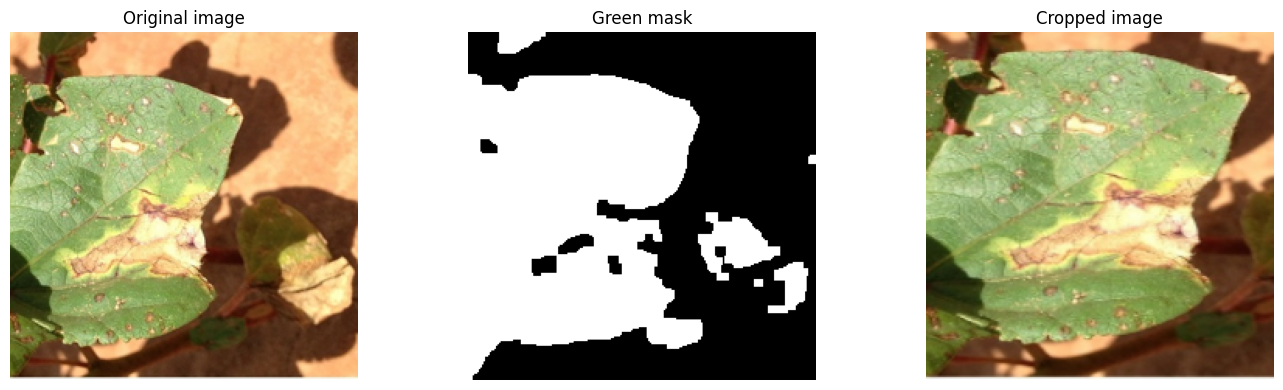

Image: /content/gdrive/MyDrive/cotton/fussarium_wilt/fus238.jpg
True label: fussarium_wilt

Original probabilities:
{'bacterial_blight': np.float32(0.3204), 'curl_virus': np.float32(0.091), 'fussarium_wilt': np.float32(0.5883), 'healthy': np.float32(0.0003)}

Cropped probabilities:
{'bacterial_blight': np.float32(0.5172), 'curl_virus': np.float32(0.0115), 'fussarium_wilt': np.float32(0.4701), 'healthy': np.float32(0.0011)}


In [ ]:
# 1. Inspect image 68

import matplotlib.pyplot as plt
import torch
import numpy as np
from PIL import Image
from torchvision import transforms

idx = 68
row = test_df_new.iloc[idx]
image_path = row["path"]

with Image.open(image_path) as img:
    original = img.convert("RGB").resize((224, 224))

cropped_array, mask = create_leaf_focused_crop(image_path)
cropped = Image.fromarray(cropped_array)

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

model.eval()

with torch.no_grad():
    original_logits = model(
        eval_transform(original).unsqueeze(0).to(device)
    )
    cropped_logits = model(
        eval_transform(cropped).unsqueeze(0).to(device)
    )

    original_probs = torch.softmax(original_logits, dim=1)[0].cpu().numpy()
    cropped_probs = torch.softmax(cropped_logits, dim=1)[0].cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(original)
axes[0].set_title("Original image")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Green mask")

axes[2].imshow(cropped)
axes[2].set_title("Cropped image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image:", image_path)
print("True label:", row["label"])
print("\nOriginal probabilities:")
print(dict(zip(class_names, np.round(original_probs, 4))))
print("\nCropped probabilities:")
print(dict(zip(class_names, np.round(cropped_probs, 4))))

Next experiment — Test background dependence more directly

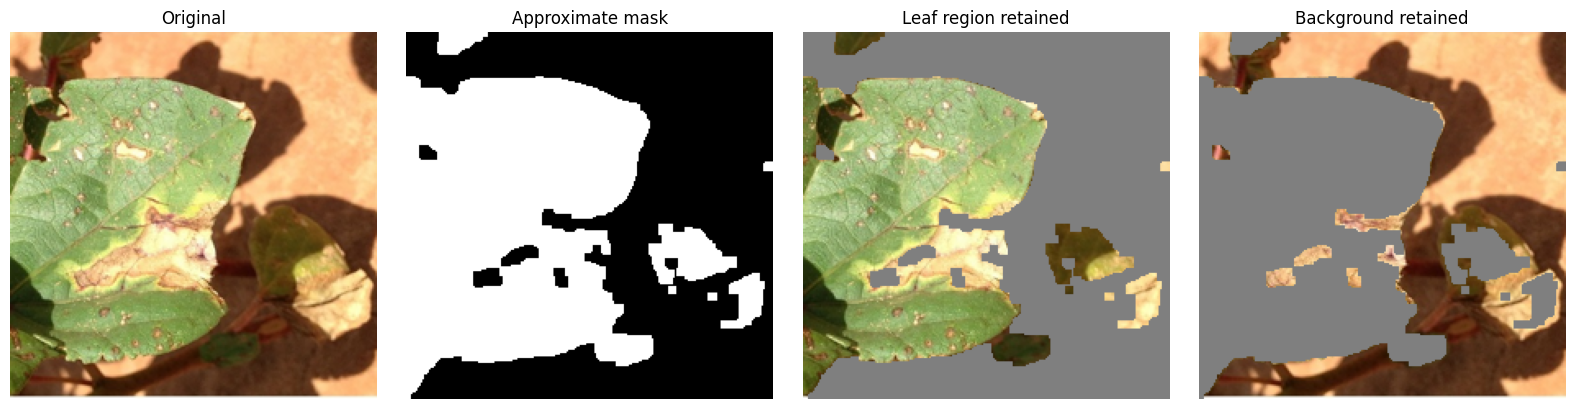

,input,prediction,confidence,prob_bacterial_blight,prob_curl_virus,prob_fussarium_wilt,prob_healthy
0,Original,fussarium_wilt,0.5883,0.3204,0.0910,0.5883,0.0003
1,Leaf region retained,fussarium_wilt,0.7672,0.2299,0.0023,0.7672,0.0007
2,Background retained,fussarium_wilt,0.9354,0.0588,0.0022,0.9354,0.0036



Three-input comparison completed successfully.


In [ ]:
# 1. CREATE THREE INPUTS AND COMPARE PREDICTIONS

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from PIL import Image
from torchvision import transforms

# 1. Load sample image

image_path = Path(
    "/content/gdrive/MyDrive/cotton/"
    "fussarium_wilt/fus238.jpg"
)

assert image_path.exists(), f"Image not found: {image_path}"

with Image.open(image_path) as img:
    original = np.asarray(
        img.convert("RGB").resize((224, 224))
    )

# 2. Generate approximate leaf mask

hsv = cv2.cvtColor(original, cv2.COLOR_RGB2HSV)

lower_green = np.array([20, 25, 20])
upper_green = np.array([100, 255, 255])

mask = cv2.inRange(hsv, lower_green, upper_green)

kernel = np.ones((5, 5), np.uint8)

mask = cv2.morphologyEx(
    mask, cv2.MORPH_CLOSE, kernel
)

mask = cv2.morphologyEx(
    mask, cv2.MORPH_OPEN, kernel
)

leaf_mask = mask > 0
background_mask = ~leaf_mask

# 3. Create leaf-only and background-only images

gray_value = 127

gray_background = np.full_like(
    original, gray_value
)

gray_leaf = np.full_like(
    original, gray_value
)

leaf_only = np.where(
    leaf_mask[..., None],
    original,
    gray_background
)

background_only = np.where(
    background_mask[..., None],
    original,
    gray_leaf
)

# 4. Define evaluation transformation

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 5. Prepare three model inputs

images = {
    "Original": original,
    "Leaf region retained": leaf_only,
    "Background retained": background_only
}

# 6. Compare model predictions

model.eval()

results = []

for name, image in images.items():

    tensor = eval_transform(
        Image.fromarray(image)
    ).unsqueeze(0).to(device)

    with torch.no_grad():

        logits = model(tensor)

        probabilities = torch.softmax(
            logits, dim=1
        )[0].cpu().numpy()

    predicted_idx = int(np.argmax(probabilities))

    results.append({
        "input": name,
        "prediction": class_names[predicted_idx],
        "confidence": float(probabilities[predicted_idx]),
        **{
            f"prob_{class_names[i]}": float(probabilities[i])
            for i in range(len(class_names))
        }
    })

# 7. Visualize all three inputs and the mask

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(original)
axes[0].set_title("Original")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Approximate mask")

axes[2].imshow(leaf_only)
axes[2].set_title("Leaf region retained")

axes[3].imshow(background_only)
axes[3].set_title("Background retained")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# 8. Display prediction comparison

results_df = pd.DataFrame(results)

display(
    results_df[
        ["input", "prediction", "confidence"]
        + [f"prob_{name}" for name in class_names]
    ].round(4)
)

print("\nThree-input comparison completed successfully.")

In [ ]:
# CONTROLLED EXPERIMENT — BACKGROUND SENSITIVITY

import cv2
import numpy as np
import pandas as pd
import torch

from PIL import Image
from pathlib import Path
from torchvision import transforms

# 1. Configure project paths

PROJECT_DIR = Path(
    "/content/gdrive/MyDrive/CottonGuard-AI"
)

RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

output_path = (
    RESULTS_DIR / "background_sensitivity_20_images.csv"
)

# 2. Select 5 test images from each class

sample_df = (
    test_df_new.groupby("label", group_keys=False)
    .sample(n=5, random_state=42)
    .reset_index(drop=True)
)

print("Selected images:", len(sample_df))
print("\nClass distribution:")
print(sample_df["label"].value_counts())

# 3. Define evaluation transformation

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 4. Create three image versions

def make_three_versions(image_path):

    with Image.open(image_path) as img:
        original = np.asarray(
            img.convert("RGB").resize((224, 224))
        )

    hsv = cv2.cvtColor(
        original,
        cv2.COLOR_RGB2HSV
    )

    mask = cv2.inRange(
        hsv,
        np.array([20, 25, 20]),
        np.array([100, 255, 255])
    )

    kernel = np.ones((5, 5), np.uint8)

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )

    leaf_mask = mask > 0

    gray = np.full_like(
        original,
        127
    )

    leaf_retained = np.where(
        leaf_mask[..., None],
        original,
        gray
    )

    background_retained = np.where(
        (~leaf_mask)[..., None],
        original,
        gray
    )

    return {
        "original": original,
        "leaf_retained": leaf_retained,
        "background_retained": background_retained
    }

# 5. Run controlled experiment

rows = []

model.eval()

for _, row in sample_df.iterrows():

    versions = make_three_versions(row["path"])

    true_label = row["label"]
    true_idx = class_names.index(true_label)

    for condition, image_array in versions.items():

        tensor = eval_transform(
            Image.fromarray(image_array)
        ).unsqueeze(0).to(device)

        with torch.no_grad():

            logits = model(tensor)

            probs = torch.softmax(
                logits,
                dim=1
            )[0].cpu().numpy()

        pred_idx = int(np.argmax(probs))

        rows.append({

            "path": row["path"],
            "true_label": true_label,
            "condition": condition,

            "prediction": class_names[pred_idx],

            "correct": pred_idx == true_idx,

            "true_class_probability": float(
                probs[true_idx]
            ),

            "predicted_class_probability": float(
                probs[pred_idx]
            ),

            **{
                f"prob_{class_names[i]}": float(probs[i])
                for i in range(len(class_names))
            }
        })

# 6. Create experiment DataFrame

experiment_df = pd.DataFrame(rows)

print("\nImages tested:", sample_df.shape[0])
print("Predictions evaluated:", experiment_df.shape[0])

# 7. Calculate summary statistics

summary = experiment_df.groupby("condition").agg(

    accuracy=("correct", "mean"),

    mean_true_class_probability=(
        "true_class_probability",
        "mean"
    ),

    mean_predicted_class_probability=(
        "predicted_class_probability",
        "mean"
    )

).round(4)

print("\n========== BACKGROUND SENSITIVITY SUMMARY ==========")

display(summary)

# 8. Compare prediction changes

prediction_table = experiment_df.pivot(

    index=["path", "true_label"],

    columns="condition",

    values="prediction"

).reset_index()

prediction_table["leaf_changed_prediction"] = (
    prediction_table["original"]
    != prediction_table["leaf_retained"]
)

prediction_table["background_changed_prediction"] = (
    prediction_table["original"]
    != prediction_table["background_retained"]
)

print("\n========== PREDICTION COMPARISON ==========")

display(prediction_table)

# 9. Save experiment results

experiment_df.to_csv(
    output_path,
    index=False
)

print("\n========== SAVING RESULTS ==========")

print("Results saved successfully!")
print("Saved to:", output_path)
print("File exists:", output_path.exists())

Selected images: 20

Class distribution:
label
bacterial_blight    5
curl_virus          5
fussarium_wilt      5
healthy             5
Name: count, dtype: int64

Images tested: 20
Predictions evaluated: 60

========== BACKGROUND SENSITIVITY SUMMARY ==========


,accuracy,mean_true_class_probability,mean_predicted_class_probability
condition,,,
background_retained,0.45,0.4592,0.6340
leaf_retained,0.90,0.8609,0.8949
original,1.00,0.9632,0.9632



========== PREDICTION COMPARISON ==========


condition,path,true_label,background_retained,leaf_retained,original,leaf_changed_prediction,background_changed_prediction
0,/content/gdrive/MyDrive/cotton/bacterial_bligh...,bacterial_blight,healthy,bacterial_blight,bacterial_blight,False,True
1,/content/gdrive/MyDrive/cotton/bacterial_bligh...,bacterial_blight,bacterial_blight,bacterial_blight,bacterial_blight,False,False
2,/content/gdrive/MyDrive/cotton/bacterial_bligh...,bacterial_blight,bacterial_blight,bacterial_blight,bacterial_blight,False,False
3,/content/gdrive/MyDrive/cotton/bacterial_bligh...,bacterial_blight,bacterial_blight,bacterial_blight,bacterial_blight,False,False
4,/content/gdrive/MyDrive/cotton/bacterial_bligh...,bacterial_blight,bacterial_blight,bacterial_blight,bacterial_blight,False,False
5,/content/gdrive/MyDrive/cotton/curl_virus/curl...,curl_virus,healthy,curl_virus,curl_virus,False,True
6,/content/gdrive/MyDrive/cotton/curl_virus/curl...,curl_virus,healthy,curl_virus,curl_virus,False,True
7,/content/gdrive/MyDrive/cotton/curl_virus/curl...,curl_virus,bacterial_blight,curl_virus,curl_virus,False,True
8,/content/gdrive/MyDrive/cotton/curl_virus/curl...,curl_virus,healthy,curl_virus,curl_virus,False,True
9,/content/gdrive/MyDrive/cotton/curl_virus/curl...,curl_virus,healthy,curl_virus,curl_virus,False,True



========== SAVING RESULTS ==========
Results saved successfully!
Saved to: /content/gdrive/MyDrive/CottonGuard-AI/results/background_sensitivity_20_images.csv
File exists: True


In [ ]:
# QUANTIFY BACKGROUND SENSITIVITY FINDINGS

import pandas as pd
from pathlib import Path

# 1. Load experiment results

RESULTS_DIR = Path(
    "/content/gdrive/MyDrive/CottonGuard-AI/results"
)

path = RESULTS_DIR / "background_sensitivity_20_images.csv"

assert path.exists(), f"Results file not found: {path}"

df = pd.read_csv(path)

print("Experiment results loaded successfully.")
print("Total predictions:", len(df))

# 2. Prediction changes relative to original

print("\n========== PREDICTION CHANGES ==========")

original = df[
    df["condition"] == "original"
][["path", "prediction"]].rename(
    columns={"prediction": "original_prediction"}
)

merged = df.merge(original, on="path")

merged["changed"] = (
    merged["prediction"] != merged["original_prediction"]
)

change_summary = (
    merged.groupby("condition")["changed"]
    .agg(["sum", "count"])
    .rename(
        columns={"sum": "changed_predictions"}
    )
)

display(change_summary)

# 3. Accuracy by true class and condition

print("\n========== ACCURACY BY CLASS ==========")

accuracy_by_class = df.pivot_table(
    index="true_label",
    columns="condition",
    values="correct",
    aggfunc="mean"
)

display(accuracy_by_class.round(3))

# 4. Mean true-class probability by class

print("\n========== TRUE-CLASS PROBABILITY ==========")

probability_by_class = df.pivot_table(
    index="true_label",
    columns="condition",
    values="true_class_probability",
    aggfunc="mean"
)

display(probability_by_class.round(3))

# 5. Overall summary

print("\n========== OVERALL CONDITION SUMMARY ==========")

overall_summary = df.groupby("condition").agg(
    accuracy=("correct", "mean"),
    mean_true_class_probability=(
        "true_class_probability", "mean"
    ),
    mean_predicted_class_probability=(
        "predicted_class_probability", "mean"
    )
).round(4)

display(overall_summary)

print("\nAnalysis completed successfully.")

Experiment results loaded successfully.
Total predictions: 60

========== PREDICTION CHANGES ==========


,changed_predictions,count
condition,,
background_retained,11,20
leaf_retained,2,20
original,0,20



========== ACCURACY BY CLASS ==========


condition,background_retained,leaf_retained,original
true_label,,,
bacterial_blight,0.8,1.0,1.0
curl_virus,0.0,1.0,1.0
fussarium_wilt,1.0,0.6,1.0
healthy,0.0,1.0,1.0



========== TRUE-CLASS PROBABILITY ==========


condition,background_retained,leaf_retained,original
true_label,,,
bacterial_blight,0.646,0.952,0.936
curl_virus,0.197,0.985,0.993
fussarium_wilt,0.790,0.542,0.928
healthy,0.204,0.964,0.995



========== OVERALL CONDITION SUMMARY ==========


,accuracy,mean_true_class_probability,mean_predicted_class_probability
condition,,,
background_retained,0.45,0.4592,0.6340
leaf_retained,0.90,0.8609,0.8949
original,1.00,0.9632,0.9632



Analysis completed successfully.
